# 04 | CANTAB, psychosocial context and the limits of brain–behaviour inference

**Learning goals:** read every assessment, preserve mixed outcomes and formulate testable network hypotheses.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## Describe before explaining
Raw score change is $\Delta = x_{post}-x_{pre}$. A direction-aligned percentage flips signs for latency, error and moves so rightward nominally means favorable. It is **not** a normative z-score, reliable-change index, effect size or global cognition score. Variability (SD) measures receive no favorable direction.

The supplied battery contains MOT, RTI, RVP, SOC and SSP. Reaction time and movement time differ; accuracy is already at ceiling in RTI. “A motor deficit” or “significant improvement” is not supported solely by these values. No control/retest distribution or assessment interval is supplied.

,measure,description,units,preop,postop,delta_post_minus_pre,percent_change
0,mot_latency_mean,CANTAB Motor Screening — mean latency,ms,817.80,844.500000,26.700000,3.264857
1,mot_latency_md,CANTAB Motor Screening — median latency,ms,797.50,861.500000,64.000000,8.025078
2,mot_error_mean,CANTAB Motor Screening — mean error (distance ...,pixels,8.69,9.667262,0.977262,11.245822
3,rti_simple_accuracy,CANTAB Reaction Time — simple: number of corre...,correct responses,9.00,9.000000,0.000000,0.000000
4,rti_simple_rt_mean,CANTAB Reaction Time — simple: mean reaction time,ms,403.78,345.555556,-58.224444,-14.419844
5,rti_simple_rt_md,CANTAB Reaction Time — simple: median reaction...,ms,391.00,325.000000,-66.000000,-16.879795
6,rti_simple_rt_sd,CANTAB Reaction Time — simple: reaction time s...,ms,48.69,51.754495,3.064495,6.293890
7,rti_simple_mt_mean,CANTAB Reaction Time — simple: mean movement time,ms,504.44,426.333333,-78.106667,-15.483837
8,rti_simple_mt_md,CANTAB Reaction Time — simple: median movement...,ms,484.00,423.000000,-61.000000,-12.603306
9,rti_simple_mt_sd,CANTAB Reaction Time — simple: movement time s...,ms,68.17,61.320877,-6.849123,-10.047121


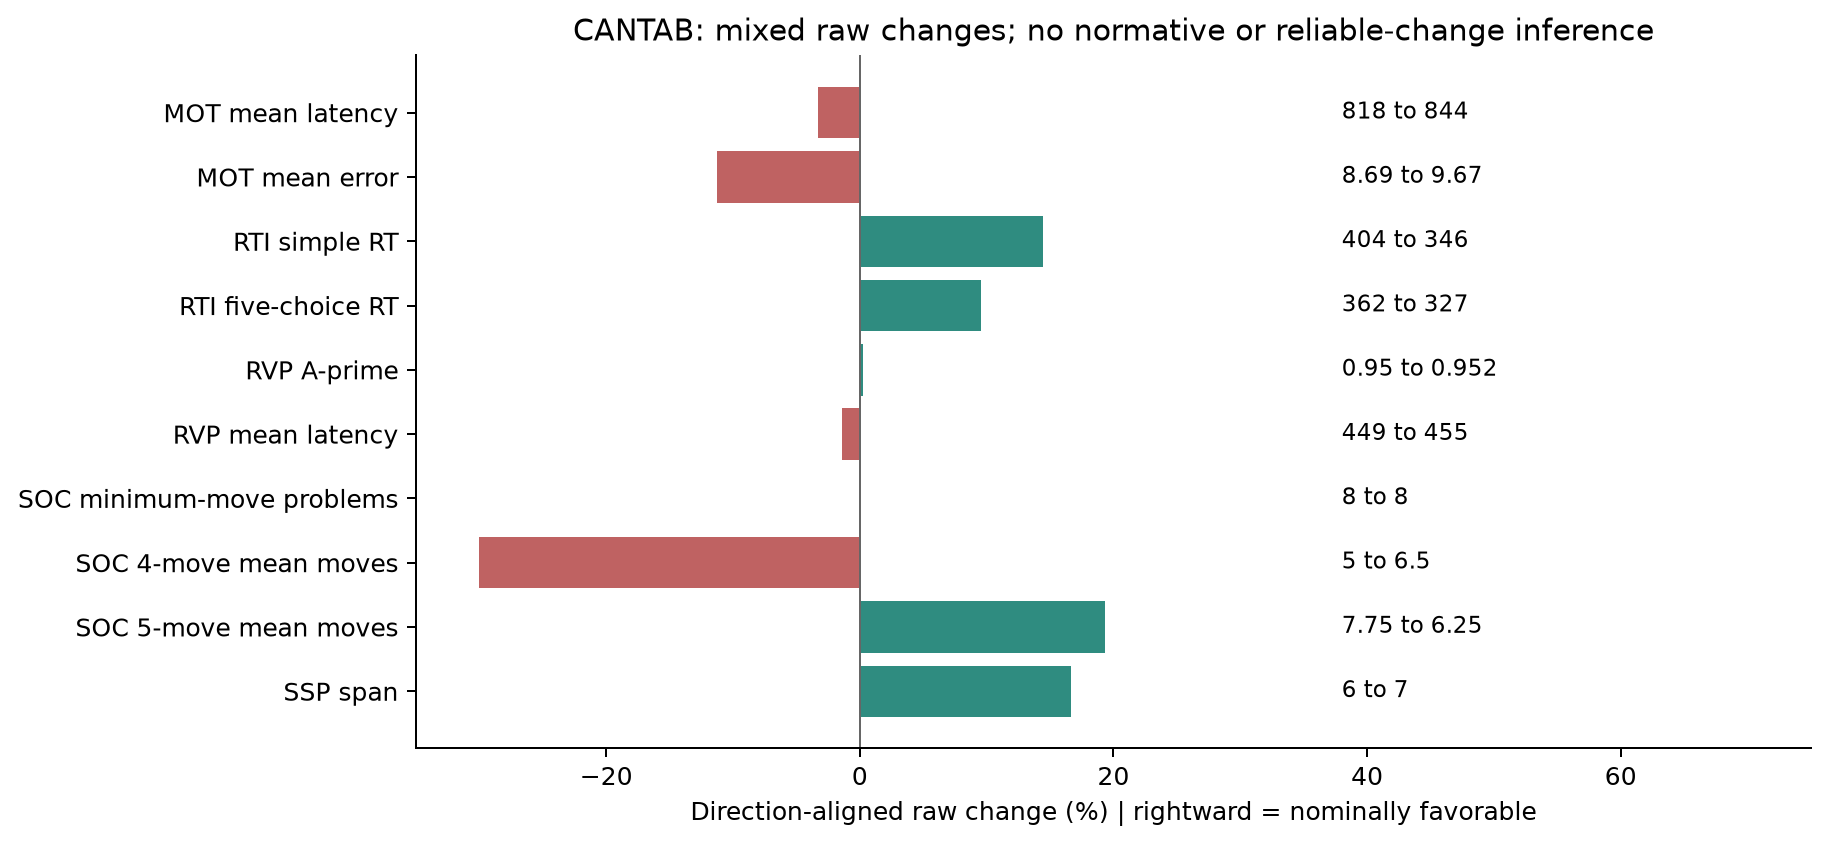

In [2]:
cantab=pd.read_csv(RESULTS/"cantab_all.csv")
display(cantab[["measure","description","units","preop","postop","delta_post_minus_pre","percent_change"]])
display(Image(filename=str(RESULTS/"figures/cognition.png")))

,measure,preop,postop,delta_post_minus_pre
0,stai,36,30,-6.0
1,pswq,54,61,7.0
2,erq_reappraisal,24,14,-10.0
3,erq_suppression,17,19,2.0
4,erq_processing,8,4,-4.0
5,erq_expression,10,8,-2.0
6,loneliness,40,50,10.0
7,marital_status,Cohabiting,Cohabiting,NaN
8,education_level,3,3,0.0
9,employment,Employed,Sickleave,NaN


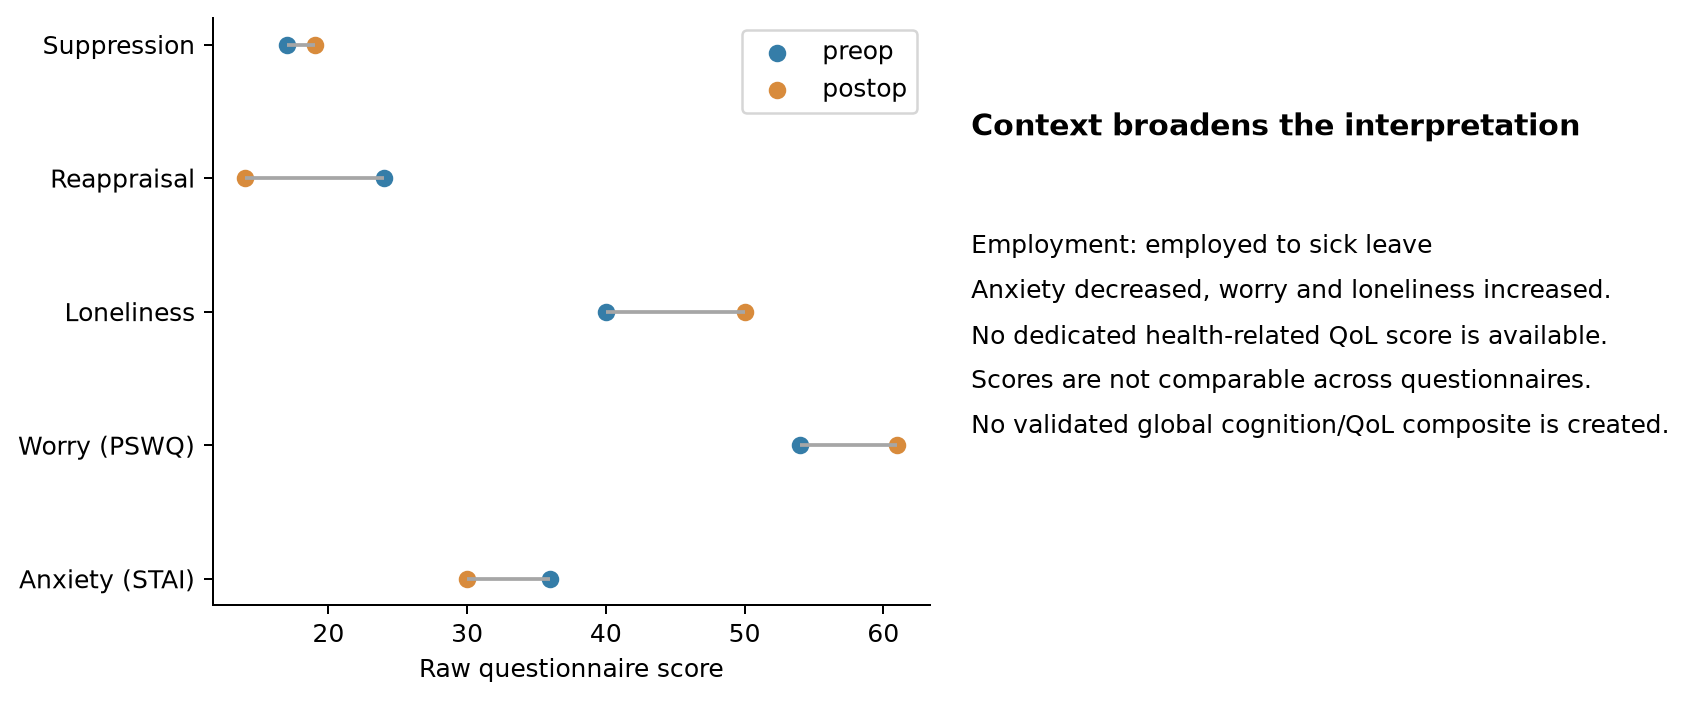

In [3]:
psych=pd.read_csv(RESULTS/"psychosocial_all.csv")
display(psych[["measure","preop","postop","delta_post_minus_pre"]])
display(Image(filename=str(RESULTS/"figures/psychosocial.png")))

## Measure dictionary: protocol, units and interpretation
The expanded report Appendices A.1/A.2 and this selector describe every field. The source JSON description is kept separately from our explanatory annotation. RTI reaction time ends at button release; movement time begins there. The unqualified `rti_five_rt` / `rti_five_mt` aggregates are not relabelled as means. RVP A-prime is not percent correct; `soc_prob_min_moves` is a **problem count** despite its name. SDs have no assigned favourable direction.

Questionnaire versions, education-code mapping and lifestyle-index formulas are unavailable. Post-op-only “Same/More/Less” fields are relative categories; missing baseline values are structural, not zero. No CANTAB norm, diagnosis or health-related QoL score is inferred.

In [4]:
dictionary=pd.read_csv(RESULTS/"assessments_all.csv").set_index("measure")
def inspect_measure(measure="rti_simple_rt_mean"):
    row=dictionary.loc[measure]
    display(row[["description","definition","domain","units","source_units","preop","postop","delta_post_minus_pre","direction_text","caveat","source_basis"]].to_frame("Value / explanation"))
widgets.interact(inspect_measure,measure=widgets.Dropdown(options=dictionary.index.tolist(),value="rti_simple_rt_mean",layout=widgets.Layout(width="550px")))

,Value / explanation
description,CANTAB Reaction Time — simple: mean reaction time
definition,Reaction Time - simple: mean reaction time; ta...
domain,Attention and psychomotor speed
units,ms
source_units,ms
preop,403.78
postop,345.5555555556
delta_post_minus_pre,-58.224444
direction_text,"Lower is nominally faster, more precise or mor..."
caveat,"Raw score; no age-adjusted norm, individual re..."


interactive(children=(Dropdown(description='measure', index=23, layout=Layout(width='550px'), options=('stai',…

<function __main__.inspect_measure(measure='rti_simple_rt_mean')>

## Hypothesis map, not reverse inference
Speeded responding recruits sensory, attentional and motor systems; planning and visuospatial span have distributed control/attention contributions. Network labels do not identify the mechanism of an individual score change. Equal-weighted “cognition predictions” are not trained on two observations.

Anxiety fell while worry and loneliness rose, and employment changed from employed to sick leave. These are relevant to lived experience, but there is no dedicated health-related QoL instrument. Lower reappraisal and higher suppression have no universal favorable direction. The source's additional ERQ “processing”/“expression” labels are preserved without asserting standard validated ERQ subscales.

In [5]:
from pat16.clinical import HYPOTHESES
hypotheses=pd.DataFrame(HYPOTHESES,columns=["test","construct","candidate_networks","interpretation"])
display(hypotheses)
net=pd.read_csv(RESULTS/"network_summary.csv")

def domain_context(test="RTI"):
    row=hypotheses.set_index("test").loc[test];display(row)
    related=row.candidate_networks.split("; ")
    display(net[net.network.isin(related)][["session","network","within_fc_fisher_z","within_sc_fraction"]] if "within_sc_fraction" in net else net[net.network.isin(related)].filter(regex="session|network|^within_"))
    primary_ranges=pd.read_csv(RESULTS/"primary_fc/network_uncertainty.csv").query("role=='primary'")
    display(primary_ranges[primary_ranges.network.isin(related)])
    display(cantab[cantab.measure.str.startswith(test.lower()+"_")][["measure","preop","postop","delta_post_minus_pre"]])
widgets.interact(domain_context,test=widgets.Dropdown(options=hypotheses.test.tolist()))

construct                               Sensorimotor / visual attention
candidate_networks                                          SomMot; Vis
interpretation        latency and spatial error; no isolated motor d...
Name: MOT, dtype: object

,session,network,within_sc_weight,within_fc_fisher_z
0,preop,Vis,2.971691,0.281717
1,preop,SomMot,2.579487,0.265161
7,postop,Vis,2.629167,0.277224
8,postop,SomMot,2.915751,0.149400


,network,modality,protocol,mode,role,units,edges,preop,postop,observed_delta,draws,q025,median,q975,sd,positive_fraction
0,Vis,SC,whole_run_bootstrap,own_reselected,primary,mean streamlines / 10000 attempted seeds,136,2.971691,2.629167,-0.342525,500,-0.385337,-0.345833,-0.307960,0.020503,0.000
15,Vis,FC,two_thirds_block10,full_refit,primary,mean Fisher z,136,0.281717,0.277224,-0.004493,200,-0.159444,-0.020886,0.108071,0.069995,0.405
28,SomMot,SC,whole_run_bootstrap,own_reselected,primary,mean streamlines / 10000 attempted seeds,91,2.579487,2.915751,0.336264,500,0.283402,0.327839,0.371245,0.023036,1.000
43,SomMot,FC,two_thirds_block10,full_refit,primary,mean Fisher z,91,0.265161,0.149400,-0.115760,200,-0.206384,-0.109317,-0.016997,0.051992,0.010


,measure,preop,postop,delta_post_minus_pre
0,mot_latency_mean,817.80,844.500000,26.700000
1,mot_latency_md,797.50,861.500000,64.000000
2,mot_error_mean,8.69,9.667262,0.977262


interactive(children=(Dropdown(description='test', options=('MOT', 'RTI', 'RVP', 'SOC', 'SSP'), value='MOT'), …

<function __main__.domain_context(test='RTI')>

## Why not correlate cognition with efficiency here?
With two time points a nonconstant correlation is mechanically ±1; it is not validation. No patient-specific predictive model or causal surgery effect can be estimated from these observations. Preserved performance despite changed connectivity could reflect redundancy, compensation, practice, measurement error or vascular effects; this design cannot separate them.

**Next study:** preregister network/domain hypotheses, obtain postoperative timing, treatment and medication details, matched retest controls or repeated assessments, normative CANTAB scores/reliability, validated QoL, neurovascular measures and improved preprocessing. Then evaluate predictions out of sample.